# 08 · Integrated risk analysis (one row per shipment)

**Goal:** combine all tables into a point-in-time-correct analytical dataset with one row per shipment, document every
join, and then ask which pre-departure conditions — together — distinguish On-Time, At-Risk and Critical shipments.

The integration code is in `eda/src/cargomind_eda/features.py`. This notebook documents and validates it.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as ss
from sklearn.feature_selection import mutual_info_classif

from cargomind_eda import io, stats, features, plotting as P
from cargomind_eda.config import CLASSES, CLASS_COLORS, INTERIM

P.setup()
T = io.load_all()

## H1. Join design

**Reference time.** No booking/prediction timestamp exists in the data. For EDA the reference is `departure_ts`, and every
time-varying source is cut off at **`cutoff_ts = departure_ts − 1 h`**: the last hourly record used is the one stamped
`cutoff_ts`. If `ts_hour` labels the *start* of an hour, that record is complete one hour before departure; if it labels the end,
the 1 h margin is conservative. Sensitivity to larger lags (24 h, 72 h) is tested in H6. The final prediction time is an open
modelling decision (notebook 09).

| Source | Grain | Key(s) | Join type | Temporal logic | Duplication risk | Expected missing |
|---|---|---|---|---|---|---|
| port_network | route | `route_id` | left, m:1 | static | none (route_id unique) | none |
| port_metadata | port | origin / dest / hub `port_id` | map, m:1 | static | none | hub fields for direct routes |
| port_hourly_telemetry | port × hour | (`port_id`, `cutoff_ts`) per role | left, m:1, exact hour | snapshot at cutoff + trailing 24 h window ending at cutoff | none (key unique, grid complete) | hub fields for direct routes; 24 h *change* for first-day departures |
| weather_hourly | port × hour | same as telemetry | left, m:1 | same | none | same |
| disruption_events | event interval | `port_id` per role | aggregate then left join | event_start ≤ cutoff < event_end (active); started in last 72 h | **one-to-many** → aggregated per shipment before joining (count / max severity / max capacity) | none (0 = no event) |
| port_traffic_history | port × day | (`port_id`, departure UTC date − 1 day) | left, m:1 | last *complete* day before departure | none | none (data starts 1 Jan, first departure 2 Jan) |
| public_holidays | country/subdivision × date | port → country (+ subdivision) | expanded then nearest-date lookup | calendar, known in advance; local dates via port timezone | holidays expanded per port, distance computed per shipment | destination holiday unknown after 26 Feb |
| shipment_records (self) | shipment | group key (route / carrier / origin / destination) | point-in-time aggregation | only shipments whose **actual arrival < cutoff** | none | early shipments with no arrived history |

**Explicitly excluded / quarantined** (prefix `LEAK_`, built only to measure leakage): destination conditions at expected
arrival, origin conditions in the 24 h after departure, events starting after departure, remaining event duration.

In [2]:
s0 = T["shipment_records"]
f = features.build_shipment_features(lag_hours=1, tables=T)
flags = pd.read_csv(INTERIM / "shipment_lineage_flags.csv")
f = f.merge(flags, on="shipment_id", how="left", validate="1:1")
print("rows in shipment_records:", len(s0), "| rows after integration:", len(f), "| unique shipment_id:", f.shipment_id.is_unique)
assert len(f) == len(s0) and f.shipment_id.is_unique

rows in shipment_records: 9850 | rows after integration: 9850 | unique shipment_id: True


### Match rates and missingness after integration

In [3]:
groups = {
    "origin telemetry (o_)": [c for c in f if c.startswith("o_") and c not in ("o_capacity_teu_per_hour", "o_region")],
    "destination telemetry (d_)": [c for c in f if c.startswith("d_") and c not in ("d_capacity_teu_per_hour", "d_region")],
    "hub telemetry (h_)": [c for c in f if c.startswith("h_") and c not in ("h_capacity_teu_per_hour", "h_region")],
    "origin weather (wx_o_)": [c for c in f if c.startswith("wx_o_")],
    "destination weather (wx_d_)": [c for c in f if c.startswith("wx_d_")],
    "hub weather (wx_h_)": [c for c in f if c.startswith("wx_h_")],
    "origin traffic (tr_o_)": [c for c in f if c.startswith("tr_o_")],
    "destination traffic (tr_d_)": [c for c in f if c.startswith("tr_d_")],
    "disruption counts (dis_*_active_n)": ["dis_o_active_n", "dis_d_active_n", "dis_h_active_n"],
    "holiday (hol_)": [c for c in f if c.startswith("hol_")],
    "historical outcomes (hist_)": [c for c in f if c.startswith("hist_")],
    "LEAK: dest at expected arrival": [c for c in f if c.startswith("LEAK_d_at_arrival") or c.startswith("LEAK_wx_d_at_arrival")],
}
rows = []
transship = f.transshipment_port_id.notna()
for g, cols in groups.items():
    miss = f[cols].isna().any(axis=1)
    rows.append({"feature group": g, "columns": len(cols), "rows with any missing": int(miss.sum()), "pct": round(miss.mean() * 100, 1),
                 "missing among transshipment routes": int(miss[transship].sum())})
pd.DataFrame(rows).set_index("feature group")

,columns,rows with any missing,pct,missing among transshipment routes
feature group,,,,
origin telemetry (o_),22,9,0.1,2
destination telemetry (d_),22,9,0.1,2
hub telemetry (h_),22,6174,62.7,2
origin weather (wx_o_),14,9,0.1,2
destination weather (wx_d_),14,9,0.1,2
hub weather (wx_h_),14,6174,62.7,2
origin traffic (tr_o_),6,0,0,0
destination traffic (tr_d_),6,0,0,0
disruption counts (dis_*_active_n),3,6172,62.7,0


* Hub features are missing exactly for direct routes (62.7 %) — **structural**, meaning "no hub". Encode as such; do not impute.
* `*_util_change24` / `*_pressure_change24` are missing for 8 shipments departing in the first 24 h of data (no prior day).
* `hist_*` features are missing where no shipment in the group had arrived before the cutoff — the "cold start" of the data
  window. Real deployment would have longer history.
* 27 % of shipments have no destination telemetry at expected arrival because it falls after 11 Feb. That variable is
  leakage anyway.
* Disruption counts are 0 (not missing) when no event applies; capacity/elapsed hours are missing when no event is active.

In [4]:
f.to_csv(INTERIM / "shipments_integrated.csv", index=False)
f.to_pickle(INTERIM / "shipments_integrated.pkl")
print(f"saved eda/data/interim/shipments_integrated.csv/.pkl  shape={f.shape}")

saved eda/data/interim/shipments_integrated.csv/.pkl  shape=(9850, 240)


## H2. Screening every safe pre-departure feature (sea shipments)

Two separations matter for this problem:
* **Critical vs On-Time** (largest gap),
* **At-Risk vs On-Time** (harder, and where most class confusion will occur).

Effect size = Cliff's δ (robust to ties and scale). Also reported: Spearman ρ with delay hours and mutual information with
the 3-class label (non-linear check).

In [5]:
sea = f[f.shipping_mode == "sea"].copy()
exclude_prefix = ("LEAK_", "filled_", "raw_label", "outcome_not")
exclude = {"actual_delay_hours", "container_teu_x"}
num_cols = [c for c in sea.columns if sea[c].dtype.kind in "fiub" and not c.startswith(exclude_prefix) and c not in exclude and sea[c].nunique() > 1]
scr = stats.screen_numeric(sea, num_cols)
mi_data = sea[num_cols].copy()
mi_data = mi_data.fillna(mi_data.median())  # for MI estimation only; does not touch the saved dataset
scr["mutual_info"] = pd.Series(mutual_info_classif(mi_data, sea.delay_status.cat.codes, random_state=0, n_neighbors=5), index=num_cols)
scr["abs_cliff_crit"] = scr["cliff_Critical_vs_On-Time"].abs()
scr = scr.sort_values("abs_cliff_crit", ascending=False)
P.save_table(scr, "08_numeric_feature_screen_sea")
scr[["n", "tie_share", "cliff_At-Risk_vs_On-Time", "cliff_Critical_vs_On-Time", "cliff_Critical_vs_At-Risk", "spearman_rho_delay_h", "mutual_info"]].round(3).head(40)

,n,tie_share,cliff_At-Risk_vs_On-Time,cliff_Critical_vs_On-Time,cliff_Critical_vs_At-Risk,spearman_rho_delay_h,mutual_info
feature,,,,,,,
dis_o_active_capacity_pct,1431,0.115,0.316,0.723,0.544,0.603,0.109
o_anchor_mean24,9347,0.087,0.309,0.54,0.238,0.39,0.102
o_anchor_max24,9347,0.38,0.293,0.526,0.235,0.383,0.086
o_vessels_at_anchor,9347,0.458,0.247,0.504,0.261,0.361,0.067
wx_o_precip_sum24,9347,0.16,0.136,0.44,0.322,0.253,0.094
wx_o_gust_max24,9347,0.016,0.136,0.439,0.339,0.259,0.153
o_container_dwell_hours,9347,0.005,0.19,0.435,0.254,0.272,0.065
dis_d_active_hours_elapsed,1428,0.042,-0.19,-0.426,-0.242,-0.309,0.043
o_dwell_mean24,9347,0.002,0.204,0.419,0.226,0.273,0.097


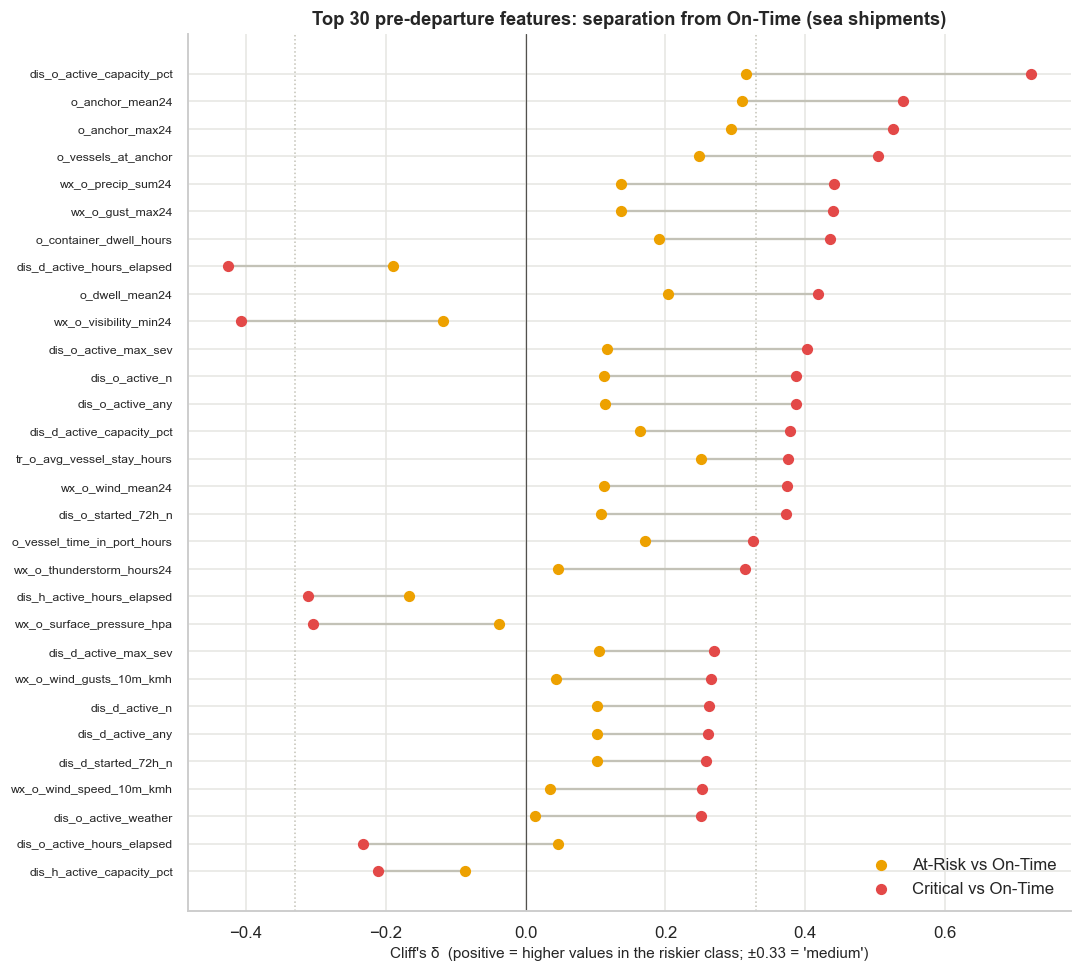

In [6]:
top = scr.head(30)
fig, ax = plt.subplots(figsize=(10, 9))
y = np.arange(len(top))
ax.scatter(top["cliff_At-Risk_vs_On-Time"], y, color=CLASS_COLORS["At-Risk"], s=40, label="At-Risk vs On-Time", zorder=3)
ax.scatter(top["cliff_Critical_vs_On-Time"], y, color=CLASS_COLORS["Critical"], s=40, label="Critical vs On-Time", zorder=3)
for i, (a, b) in enumerate(zip(top["cliff_At-Risk_vs_On-Time"], top["cliff_Critical_vs_On-Time"])):
    ax.plot([a, b], [i, i], color="#c3c2b7", lw=1.5, zorder=2)
ax.axvline(0, color="#52514e", lw=0.8)
for v in (-0.33, 0.33):
    ax.axvline(v, color="#c3c2b7", ls=":", lw=1)
ax.set_yticks(y, top.index, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Cliff's δ  (positive = higher values in the riskier class; ±0.33 = 'medium')")
ax.set_title("Top 30 pre-departure features: separation from On-Time (sea shipments)")
ax.legend(loc="lower right")
P.save(fig, "08_top_features_cliffs_delta")

In [7]:
sea["hub"] = sea.transshipment_port_id.fillna("direct")
for c in ["o_labour_status", "d_labour_status", "h_labour_status"]:
    sea[c] = sea[c].fillna("no hub")
cat_cols = ["origin_port_id", "destination_port_id", "hub", "route_type", "carrier", "cargo_type", "shipment_priority",
            "o_labour_status", "d_labour_status", "h_labour_status", "o_region", "d_region"]
cs = stats.screen_categorical(sea, cat_cols).sort_values("cramers_v", ascending=False)
P.save_table(cs, "08_categorical_feature_screen_sea")
cs[["levels", "cramers_v", "p_value", "min_expected"]].round(4)

,levels,cramers_v,p_value,min_expected
feature,,,,
route_type,2,0.1847,0,549.7
origin_port_id,10,0.1621,0,64.63
h_labour_status,4,0.139,0,18.65
hub,5,0.1324,0,93.55
o_labour_status,3,0.1205,0,55.15
carrier,6,0.1153,0,171.9
o_region,6,0.1029,0,117.2
d_labour_status,3,0.085,0,52.62
shipment_priority,3,0.0824,0,292


## H3. Redundancy among informative features

In [8]:
cand = scr[scr.abs_cliff_crit >= 0.15].index.tolist()
corr = sea[cand].corr("spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().rename("rho").reset_index()
         .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
high = pairs[pairs.rho.abs() >= 0.8].sort_values("rho", key=abs, ascending=False)
P.save_table(high.set_index(["feature_a", "feature_b"]), "08_redundant_pairs")
print(f"{len(cand)} candidate features with |δ| ≥ 0.15; {len(high)} pairs with |ρ| ≥ 0.8")
high.head(40)

48 candidate features with |δ| ≥ 0.15; 22 pairs with |ρ| ≥ 0.8


,feature_a,feature_b,rho
1033,planned_duration_h,planned_transit_hours,1
824,dis_d_active_n,dis_d_active_any,0.9992
460,dis_o_active_n,dis_o_active_any,0.9992
424,dis_o_active_max_sev,dis_o_active_any,0.9964
775,dis_d_active_max_sev,dis_d_active_any,0.9964
423,dis_o_active_max_sev,dis_o_active_n,0.9958
774,dis_d_active_max_sev,dis_d_active_n,0.9957
988,hist_carrier_pct_delayed,hist_carrier_mean_delay_h,0.9827
464,dis_o_active_n,dis_o_started_72h_n,0.9748
499,dis_o_active_any,dis_o_started_72h_n,0.974


sparse features left out of the clustermap: ['dis_o_active_capacity_pct', 'dis_d_active_hours_elapsed', 'dis_d_active_capacity_pct', 'dis_h_active_hours_elapsed', 'dis_o_active_hours_elapsed', 'dis_h_active_capacity_pct', 'h_util_mean24', 'hol_h_days_in_voyage', 'h_util_max24']


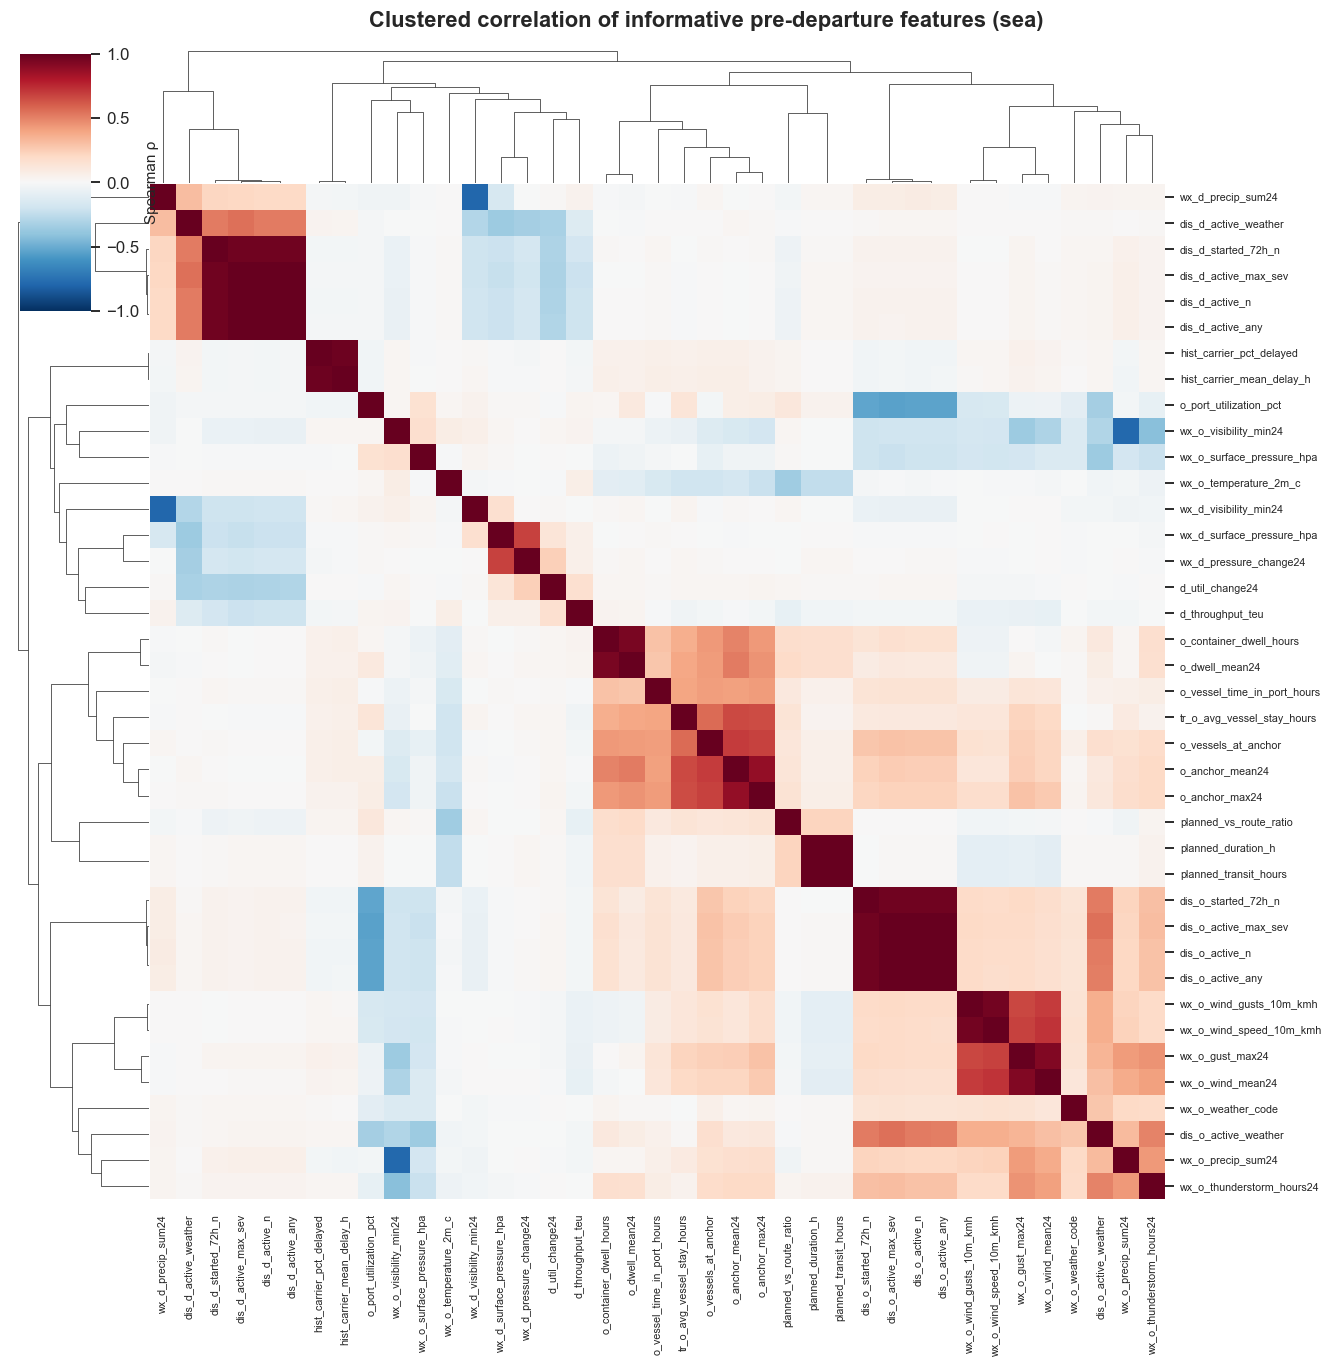

In [9]:
# Clustering needs a complete matrix: use features observed for ≥ 90 % of sea shipments (hub / active-event detail
# features are sparse by construction and are covered by the pair table above).
dense = [c for c in cand if sea[c].notna().mean() >= 0.9]
print("sparse features left out of the clustermap:", [c for c in cand if c not in dense])
corr = sea[dense].corr("spearman").fillna(0)
g = sns.clustermap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, figsize=(13, 13), xticklabels=True, yticklabels=True,
                   cbar_kws={"label": "Spearman ρ"}, dendrogram_ratio=0.12)
g.ax_heatmap.tick_params(labelsize=7)
g.fig.suptitle("Clustered correlation of informative pre-departure features (sea)", y=1.01, fontweight="semibold")
g.savefig(ROOT / "reports" / "figures" / "08_feature_correlation_clustermap.png", bbox_inches="tight", dpi=130)

## H4. How conditions combine

In [10]:
sea["origin_event"] = np.where(sea.dis_o_active_any == 1, "origin event active", "no origin event")
sea["anchor_hi"] = np.where(sea.o_anchor_mean24 > 2, "anchor queue > 2", "anchor queue ≤ 2")
sea["route_kind"] = sea.route_type
tab = sea.groupby(["origin_event", "anchor_hi", "route_kind"]).agg(n=("delay_status", "size"),
        pct_delayed=("delay_status", lambda x: (x != "On-Time").mean() * 100), pct_critical=("delay_status", lambda x: (x == "Critical").mean() * 100)).round(1)
tab

n  pct_delayed  pct_critical
origin_event        anchor_hi        route_kind                                    
no origin event     anchor queue > 2 direct         1180         60.3          15.1
                                     transshipment   665         83.2          38.2
                    anchor queue ≤ 2 direct         3797           26           4.5
                                     transshipment  2274         44.9           9.6
origin event active anchor queue > 2 direct          382         80.9          40.8
                                     transshipment   207         91.8          62.3
                    anchor queue ≤ 2 direct          509         74.7          38.5
                                     transshipment   333         82.6            52

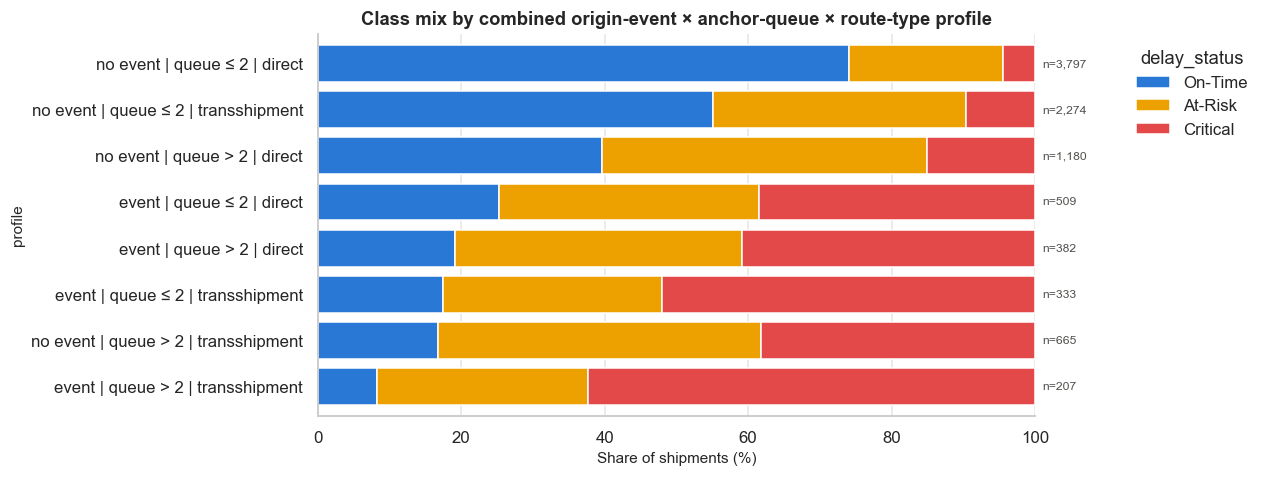

In [11]:
fig, ax = plt.subplots(figsize=(12, 4.5))
sea["profile"] = sea.origin_event.str.replace("origin event active", "event").str.replace("no origin event", "no event") + " | " + \
    sea.anchor_hi.str.replace("anchor queue ", "queue ") + " | " + sea.route_kind
P.stacked_class_bar(sea, "profile", ax=ax, title="Class mix by combined origin-event × anchor-queue × route-type profile")
P.save(fig, "08_combined_profiles")

### Coverage: how many delayed shipments have *any* visible adverse precondition?

In [12]:
adverse = pd.DataFrame({
    "origin event active": sea.dis_o_active_any == 1,
    "origin anchor 24h mean > 2": sea.o_anchor_mean24 > 2,
    "origin max gust 24h > 50 km/h": sea.wx_o_gust_max24 > 50,
    "origin holiday ±2 d": sea.hol_o_within_2d == 1,
    "hub event active": sea.dis_h_active_any == 1,
    "transshipment": sea.route_type == "transshipment",
})
cov = adverse.groupby(sea.delay_status, observed=True).mean().T * 100
cov.loc["ANY of the above except transshipment"] = adverse.drop(columns="transshipment").any(axis=1).groupby(sea.delay_status, observed=True).mean() * 100
cov.loc["NONE (incl. direct route)"] = (~adverse.any(axis=1)).groupby(sea.delay_status, observed=True).mean() * 100
cov.round(1)

delay_status,On-Time,At-Risk,Critical
origin event active,5.6,16.9,44.3
origin anchor 24h mean > 2,13.6,35.5,48.5
origin max gust 24h > 50 km/h,3.1,13.5,49.3
origin holiday ±2 d,15,22.4,30
hub event active,5.5,5.3,6
transshipment,29.3,42.9,52.5
ANY of the above except transshipment,32.3,61.3,87.1
NONE (incl. direct route),49.6,19.9,5.1


In [13]:
q1, q3 = sea.actual_delay_hours.quantile([0.25, 0.75])
ext = sea[sea.actual_delay_hours > q3 + 3 * (q3 - q1)]
print(f"extreme delays (> Q3 + 3·IQR = {q3 + 3*(q3-q1):.0f} h): {len(ext)}")
print("…with an origin event active at departure:", int(ext.dis_o_active_any.sum()), "| with any visible adverse precondition:",
      int(adverse.loc[ext.index].drop(columns="transshipment").any(axis=1).sum()))

extreme delays (> Q3 + 3·IQR = 140 h): 28
…with an origin event active at departure: 28 | with any visible adverse precondition: 28


## H5. Leakage contrast: future information vs what is knowable

In [14]:
pairs_leak = [
    ("d_anchor_mean24", "LEAK_d_at_arrival_anchor_mean24" if "LEAK_d_at_arrival_anchor_mean24" in sea else "LEAK_d_at_arrival_anchor_max24"),
    ("d_util_mean24", "LEAK_d_at_arrival_util_mean24"),
    ("o_anchor_max24", "LEAK_o_next24_anchor_max24"),
    ("wx_o_gust_max24", "LEAK_wx_o_next24_gust_max24"),
    ("dis_o_active_n", "LEAK_dis_o_future_n"),
    ("dis_d_active_n", "LEAK_dis_d_future_n"),
]
rows = []
for safe, leak in pairs_leak:
    a = stats.numeric_vs_target(sea, safe)
    b = stats.numeric_vs_target(sea, leak)
    rows.append({"known at cutoff": safe, "δ Crit vs OT (known)": a["cliff_Critical_vs_On-Time"], "future / leaky": leak,
                 "δ Crit vs OT (future)": b["cliff_Critical_vs_On-Time"], "n (future)": b["n"]})
pd.DataFrame(rows).round(3)

,known at cutoff,δ Crit vs OT (known),future / leaky,δ Crit vs OT (future),n (future)
0,d_anchor_mean24,0.108,LEAK_d_at_arrival_anchor_max24,-0.031,6663
1,d_util_mean24,0.058,LEAK_d_at_arrival_util_mean24,0.051,6663
2,o_anchor_max24,0.526,LEAK_o_next24_anchor_max24,0.605,9129
3,wx_o_gust_max24,0.439,LEAK_wx_o_next24_gust_max24,0.233,9129
4,dis_o_active_n,0.387,LEAK_dis_o_future_n,0.049,9347
5,dis_d_active_n,0.262,LEAK_dis_d_future_n,0.105,9347


**Result (contrary to the usual expectation):** future information adds little here. Destination conditions *at expected
arrival* do not separate classes (δ ≈ −0.03 to 0.05), and events that start after departure are weak (origin δ = 0.05,
destination δ = 0.10). The exception is the origin anchor queue in the 24 h *after* departure (δ = 0.61 vs 0.53 known). It
continues a backlog that is already visible at departure, so most of its information is available in the pre-departure
value. In this dataset, risk appears to be largely **determined by origin conditions at or before departure**, which is good
news for a departure-time model. These `LEAK_` variables must still never be features: they are unavailable in deployment,
and their weakness here is an empirical result for this dataset, not a guarantee.

## H6. Sensitivity to the prediction cutoff (lag)
If predictions are made earlier (24 h or 72 h before departure), how much of the signal survives?

,lag 1 h,lag 6 h,lag 24 h,lag 72 h
dis_o_active_any,0.386,0.317,0.228,0.152
dis_o_active_max_sev,0.403,0.333,0.238,0.148
o_anchor_mean24,0.54,0.481,0.32,0.27
o_container_dwell_hours,0.435,0.411,0.37,0.333
wx_o_gust_max24,0.439,0.402,0.159,-0.079
wx_o_precip_sum24,0.44,0.397,0.163,-0.037
o_vessel_time_in_port_hours,0.326,0.277,0.261,0.206
h_util_mean24,0.183,0.164,0.091,-0.037
dis_h_active_any,-0.072,-0.096,-0.038,0.033
hist_origin_port_id_pct_delayed,0.016,0.016,0.025,0.024


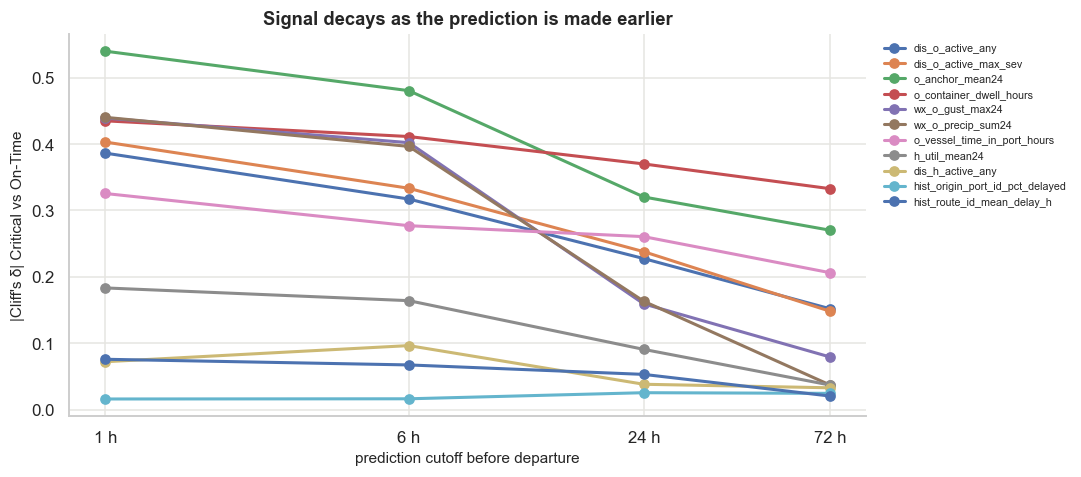

In [15]:
lag_rows = {}
key_feats = ["dis_o_active_any", "dis_o_active_max_sev", "o_anchor_mean24", "o_container_dwell_hours", "wx_o_gust_max24",
             "wx_o_precip_sum24", "o_vessel_time_in_port_hours", "h_util_mean24", "dis_h_active_any", "hist_origin_port_id_pct_delayed", "hist_route_id_mean_delay_h"]
for lag in (1, 6, 24, 72):
    fl = features.build_shipment_features(lag_hours=lag, tables=T)
    fl = fl[fl.shipping_mode == "sea"]
    lag_rows[f"lag {lag} h"] = {c: stats.numeric_vs_target(fl, c)["cliff_Critical_vs_On-Time"] for c in key_feats}
lag_tab = pd.DataFrame(lag_rows)
P.save_table(lag_tab, "08_lag_sensitivity")
fig, ax = plt.subplots(figsize=(10, 4.5))
for c in key_feats:
    ax.plot([1, 6, 24, 72], lag_tab.loc[c].abs(), marker="o", label=c)
ax.set_xscale("log")
ax.set_xticks([1, 6, 24, 72], ["1 h", "6 h", "24 h", "72 h"])
ax.set_xlabel("prediction cutoff before departure")
ax.set_ylabel("|Cliff's δ| Critical vs On-Time")
ax.set_title("Signal decays as the prediction is made earlier")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
P.save(fig, "08_lag_sensitivity")
lag_tab.round(3)

## H7. Stability of key relationships over time
Are the main associations stable across the six weeks, or driven by one episode?

In [16]:
sea["period"] = pd.cut(sea.departure_ts, pd.to_datetime(["2025-01-01", "2025-01-15", "2025-01-29", "2025-02-12"], utc=True),
                       labels=["2–14 Jan", "15–28 Jan", "29 Jan–11 Feb"])
stab = {}
for p, g in sea.groupby("period", observed=True):
    stab[p] = {c: ss.spearmanr(g[c], g.actual_delay_hours, nan_policy="omit")[0] for c in
               ["o_anchor_mean24", "o_container_dwell_hours", "wx_o_gust_max24", "dis_o_active_max_sev", "hist_origin_port_id_pct_delayed"]}
    stab[p]["n"] = len(g)
    stab[p]["% delayed"] = (g.delay_status != "On-Time").mean() * 100
pd.DataFrame(stab).round(3)

,2–14 Jan,15–28 Jan,29 Jan–11 Feb
o_anchor_mean24,0.313,0.458,0.354
o_container_dwell_hours,0.218,0.35,0.219
wx_o_gust_max24,0.232,0.303,0.231
dis_o_active_max_sev,0.349,0.398,0.301
hist_origin_port_id_pct_delayed,-0.002,-0.028,0.072
n,"3,042","3,176","3,129"
% delayed,44.54,56.96,40.4


## H8. Findings — integrated analysis

* The integration produces exactly **one row per shipment (9,850)**: no duplication, every join validated m:1 (disruptions
  aggregated before joining). The only missingness is structural: no hub (62.7 %), no arrived history yet (14.7 % for
  `hist_*`), no active event, and 8 first-day departures without a 24 h change.
* **The strongest pre-departure signals are time-varying origin conditions** (Cliff's δ Critical vs On-Time): capacity loss of
  an active origin event 0.72 (among the 15 % with one), anchor queue 24 h mean 0.54, precipitation 24 h 0.44, max gust 24 h
  0.44, container dwell 0.44, visibility −0.41, disruption severity 0.40. Static attributes add a second, independent layer:
  route type V = 0.18, origin V = 0.16, hub V = 0.13, carrier V = 0.12, priority V = 0.08, cargo V = 0.07.
* **Conditions combine.** No origin event + queue ≤ 2 + direct route → 26 % delayed, 4.5 % Critical. Origin event + queue > 2
  + transshipment → 92 % delayed, 62 % Critical (H4).
* **Coverage:** 87 % of Critical shipments and 61 % of At-Risk shipments had at least one visible adverse origin condition
  (event, queue > 2, gust > 50 km/h, holiday), vs 32 % of On-Time. **All 28 extreme sea delays (> 140 h) departed during an
  active origin disruption.** Critical delays are largely foreseeable at departure in this data.
* **At-Risk vs On-Time separation is much weaker** than Critical vs On-Time for almost every feature (e.g. gust δ 0.14 vs 0.44).
  The middle class will be the hardest to predict and the main source of confusion.
* **Point-in-time historical outcome rates are weak** (origin history δ ≈ 0.02, route mean-delay history δ ≈ 0.08). Arrivals lag
  departures by ~10 days, so history reflects past episodes, not current ones. The strong static origin effect comes from the
  *current* operating state, not a stable port "reputation". (Notebook 09 shows that a naive full-data target encoding would
  look far stronger — leakage.)
* **Redundancy:** 22 pairs with |ρ| ≥ 0.8 among 48 informative features. Examples: disruption count ≈ any ≈ severity ≈ started-72 h;
  gusts ≈ wind speed; dwell snapshot ≈ dwell 24 h mean; planned duration ≡ planned transit hours (sea); active-event capacity ≈
  −utilization; carrier history mean ≈ rate. Keep one per cluster.
* **Prediction cutoff matters.** Moving the cutoff from 1 h to 24 h before departure cuts the weather signal by ~2/3 (gust δ 0.44 →
  0.16) and the anchor signal by 40 % (0.54 → 0.32). At 72 h, weather carries no signal. Dwell time decays least (0.44 → 0.33).
* **Relationships are stable in sign** across the three fortnights (anchor ρ 0.31–0.46, gust ρ 0.23–0.30), though magnitudes vary
  with the overall delay level (40–57 % delayed per fortnight).